# 02 · Baselines

Before building a neural network we need numbers to beat. Two baselines:

1. **Lazy model**: always predicts "legit". It shows why accuracy is the wrong metric.
2. **Logistic regression**: the simplest real model, with and without class weights.

In [1]:
from pathlib import Path

# Reload the project packages automatically, so code edits show up without restarting the kernel.
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FIGURES = Path("../reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

# Fixed colors: blue is always "legit", orange is always "fraud".
LEGIT, FRAUD = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=[LEGIT, FRAUD, "#1baf7a", "#eda100"]),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "figure.dpi": 110,
})

In [2]:
from fraud_core.features import Preprocessor
from fraud_training.data import load_raw, split_by_time
from fraud_training.evaluate import confusion, evaluate, plot_pr_curves, results_table
from fraud_training.train import train_lazy, train_logistic

## Split first, then preprocess

The split happens on the raw data. The `Preprocessor` is fitted on train only and then applied to cv; the test set stays untouched until the very end of the project.

In [3]:
split = split_by_time(load_raw())
split.summary()

,from,to,rows,frauds,fraud_rate_%
train,2019-01-01,2019-12-31,924850,5220,0.564
cv,2020-01-01,2020-06-21,371825,2286,0.615
test,2020-06-21,2020-12-31,555719,2145,0.386


In [4]:
prep = Preprocessor().fit(split.train)
X_train, y_train = prep.transform(split.train)
X_cv, y_cv = prep.transform(split.cv)
print(X_train.shape, X_cv.shape)
prep.feature_names

(924850, 22) (371825, 22)


['numeric__log_amt',
 'numeric__hour',
 'numeric__day_of_week',
 'numeric__age',
 'numeric__log_city_pop',
 'numeric__distance_km',
 'categorical__category_entertainment',
 'categorical__category_food_dining',
 'categorical__category_gas_transport',
 'categorical__category_grocery_net',
 'categorical__category_grocery_pos',
 'categorical__category_health_fitness',
 'categorical__category_home',
 'categorical__category_kids_pets',
 'categorical__category_misc_net',
 'categorical__category_misc_pos',
 'categorical__category_personal_care',
 'categorical__category_shopping_net',
 'categorical__category_shopping_pos',
 'categorical__category_travel',
 'categorical__gender_F',
 'categorical__gender_M']

## Train and evaluate

In [5]:
models = {
    "lazy": train_lazy(X_train, y_train),
    "logistic": train_logistic(X_train, y_train),
    "logistic (balanced)": train_logistic(X_train, y_train, class_weight="balanced"),
}
probs = {name: m.predict_proba(X_cv)[:, 1] for name, m in models.items()}
results = {name: evaluate(y_cv, p) for name, p in probs.items()}
results_table(results)

,accuracy,precision,recall,f1,pr_auc,roc_auc
logistic,0.9942,0.7059,0.0840,0.1501,0.3505,0.8435
logistic (balanced),0.7484,0.0179,0.7428,0.0350,0.1653,0.8598
lazy,0.9939,0.0000,0.0000,0.0000,0.0061,0.5000


The lazy model is 99.4% accurate and catches **zero** frauds. Logistic regression has almost the same accuracy and catches a few. Accuracy cannot tell them apart; recall and PR-AUC can.

In [6]:
confusion(y_cv, probs["logistic"])

,pred: legit,pred: fraud
actual: legit,369459,80
actual: fraud,2094,192


In [7]:
confusion(y_cv, probs["logistic (balanced)"])

,pred: legit,pred: fraud
actual: legit,276591,92948
actual: fraud,588,1698


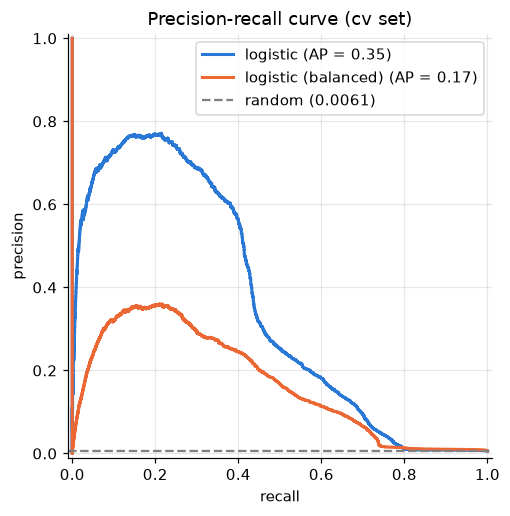

In [8]:
ax = plot_pr_curves(y_cv, {k: v for k, v in probs.items() if k != "lazy"})
ax.figure.savefig(FIGURES / "pr_curve_baselines.png", bbox_inches="tight")

## Why is logistic regression so weak here?

Both logistic models land far from a useful detector, and class weights make PR-AUC *worse*. Weighting only changes how much each fraud counts; it cannot give a linear model shapes it is unable to draw.

Logistic regression adds up one weight per feature, so each feature can only push the score up or down in a straight line. The coefficients show what it learned:

In [9]:
coefs = pd.Series(models["logistic (balanced)"].coef_[0], index=prep.feature_names).sort_values()
coefs

categorical__category_home             -1.475987
categorical__category_entertainment    -1.158917
categorical__category_food_dining      -0.957924
categorical__category_health_fitness   -0.764445
categorical__category_kids_pets        -0.443939
categorical__gender_M                  -0.356188
categorical__category_shopping_pos     -0.300666
categorical__gender_F                  -0.272012
categorical__category_personal_care    -0.254868
numeric__day_of_week                   -0.027424
numeric__distance_km                    0.008659
numeric__age                            0.050437
numeric__log_city_pop                   0.060011
categorical__category_shopping_net      0.222677
categorical__category_misc_net          0.316923
numeric__hour                           0.389354
categorical__category_misc_pos          0.526768
categorical__category_grocery_pos       0.719733
categorical__category_grocery_net       0.728583
categorical__category_travel            0.896160
numeric__log_amt    

The `hour` weight is positive, so the model believes "later is riskier". That captures the 22h-23h peak but gets 0h-3h exactly backwards, since those hours have small numbers. The same limitation applies to combinations such as "large amount **and** online store". A neural network can learn these shapes on its own, which makes this dataset a good fit for one.

**Baselines to beat: the logistic regression PR-AUC on cv.**